In [1]:
import importlib.util
import subprocess
import sys

# Keep Colab's existing PyTorch/CUDA installation; install only missing packages.
packages = {"kagglehub": "kagglehub", "torch": "torch", "numpy": "numpy",
            "pandas": "pandas", "PIL": "pillow", "matplotlib": "matplotlib", "IPython": "ipython"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import hashlib
import json
import random
import re
import shutil
import time
from datetime import datetime, timezone
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from IPython.display import FileLink, display

SEED = 42
IMG_SIZE = 512
BATCH_SIZE = 2
EPOCHS = 15
LEARNING_RATE = 1e-4
VALIDATION_SIZE = 4
EPOCH_METRIC_THRESHOLD = 0.5
DATASET_HANDLE = "andrewmvd/drive-digital-retinal-images-for-vessel-extraction"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

project_dir = (Path("/content") if Path("/content").is_dir() else Path.cwd()) / "retinal-vessel-segmentation-unet"
run_dir = project_dir / "runs" / datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
results_dir = run_dir / "results"
sample_dir = results_dir / "sample_predictions"
model_dir = run_dir / "models"
for directory in (results_dir, sample_dir, model_dir):
    directory.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = model_dir / "best_unet_retinal_vessel_segmentation.pth"

print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU runtime detected; select a GPU in Colab for the 15-epoch training cell.")
print("Configuration:", {"image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
                         "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "seed": SEED})
print("All outputs for this run:", run_dir)

SOURCE_NOTEBOOK = {'url': 'https://github.com/BensuVarol/retinal-vessel-segmentation-unet/blob/main/notebook/retinal_vessel_segmentation_unet.ipynb', 'git_blob_sha': 'd6d8a668ad2e58973ed11b746ef90808f1bc452b', 'local_partial_notebook_sha256': 'ce980c88129d778126825c807b045f6830be9f32aba5cdf91b9db2aae1233f44'}


PyTorch: 2.11.0+cu130 | Device: cuda
GPU: Tesla T4
Configuration: {'image_size': 512, 'batch_size': 2, 'epochs': 15, 'learning_rate': 0.0001, 'seed': 42}
All outputs for this run: /content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z


In [2]:
import os
import zipfile

# Optional existing best state_dict: upload it to Colab or point to its Drive path.
# Empty means look for a compatible earlier run in this Colab project directory.
EXISTING_CHECKPOINT_PATH = ""
EXISTING_RUN_SUMMARY_PATH = ""  # optional metrics.json / results_summary.json
REUSE_COMPATIBLE_CHECKPOINT = True
TRAIN_IF_CHECKPOINT_MISSING = True  # original 15-epoch cell, run only by you in Colab

# Test labels are NOT published in the currently verified official download.
# Supply only lawfully obtained, authentic first-observer vessel annotations.
TEST_LABELS_DIRECTORY = ""  # folder containing test/1st_manual or 1st_manual
TEST_LABELS_ZIP_PATH = ""   # optional local ZIP instead of a folder
TEST_LABELS_SOURCE_URL = ""
TEST_LABELS_ACCESS_NOTES = ""  # source/version and applicable access/use terms

# Optional persistent backup. This mount is performed only when explicitly enabled here.
PERSIST_CHECKPOINT_TO_DRIVE = False
DRIVE_BACKUP_DIRECTORY = "/content/drive/MyDrive/Retinal_UNet_Checkpoints"
if PERSIST_CHECKPOINT_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

ANNOTATION_SOURCE_REVIEW = {
    "checked_on": "2026-10-23",
    "official_source": "https://drive.grand-challenge.org/",
    "official_download": "https://drive.grand-challenge.org/Download/",
    "official_policy": "Test annotations are not made available; the evaluation server compares submitted predictions to hidden gold standards.",
    "reference_archive_source": "https://constantinpape.github.io/torch-em/torch_em/data/datasets/medical/drive.html",
    "reference_test_archive_sha256": "d76c95c98a0353487ffb63b3bb2663c00ed1fde7d8fdfd8c3282c6e310a02731",
    "reference_archive_checked": "20 test images and FOV masks; no manual vessel labels",
    "reference_image_version_check": "All 20 reference-archive test images matched the Kaggle test images pixel-for-pixel in RGB.",
    "licensed_manual_test_label_source_verified": False,
    "access_and_license": "Official download access is via the DRIVE website. No separately licensed manual-test-label download was verified; third-party code licenses do not establish data rights.",
}
print("Annotation source status:", ANNOTATION_SOURCE_REVIEW["official_policy"])
print("A numeric local test score requires all 20 authentic manual vessel masks.")


Annotation source status: Test annotations are not made available; the evaluation server compares submitted predictions to hidden gold standards.
A numeric local test score requires all 20 authentic manual vessel masks.


In [3]:
dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE))

# Read the cache directly instead of deleting/copying a previous data directory.
candidates = {path.parent for path in dataset_path.rglob("training")
              if (path / "images").is_dir() and (path / "1st_manual").is_dir()}
if (dataset_path / "training" / "images").is_dir():
    candidates.add(dataset_path)
if len(candidates) != 1:
    raise RuntimeError(f"Expected one DRIVE root with training/images and training/1st_manual; found {sorted(candidates)}")
data_dir = candidates.pop()


def get_image_id(path):
    match = re.match(r"^(\d{2})_", Path(path).name)
    if match is None:
        raise ValueError(f"Invalid DRIVE filename: {path}")
    return match.group(1)


def index_by_id(paths, description):
    indexed = {}
    for path in sorted(paths):
        image_id = get_image_id(path)
        if image_id in indexed:
            raise ValueError(f"Duplicate {description} ID {image_id}: {indexed[image_id]}, {path}")
        indexed[image_id] = path
    return indexed


def pair_manual_vessel_masks(image_dir, manual_dir):
    if manual_dir.name != "1st_manual":
        raise ValueError("Use manual vessel labels from 1st_manual, never the FOV mask directory.")
    images_by_id = index_by_id(image_dir.glob("*.tif"), "image")
    mask_paths = sorted(manual_dir.glob("*.gif"))
    if not all(path.name.endswith("_manual1.gif") for path in mask_paths):
        raise ValueError("Unexpected files in the manual vessel label directory.")
    masks_by_id = index_by_id(mask_paths, "manual vessel mask")
    if not images_by_id or images_by_id.keys() != masks_by_id.keys():
        raise ValueError(
            f"Image/manual-mask IDs do not match: missing masks {sorted(images_by_id.keys() - masks_by_id.keys())}; "
            f"missing images {sorted(masks_by_id.keys() - images_by_id.keys())}"
        )
    pairs = [(images_by_id[key], masks_by_id[key]) for key in sorted(images_by_id)]
    for image_path, mask_path in pairs:
        with Image.open(image_path) as image, Image.open(mask_path) as mask:
            if image.size != mask.size:
                raise ValueError(f"Image/mask dimensions differ: {image_path.name}, {mask_path.name}")
            values = np.unique(np.array(mask.convert("L")))
            if not np.all(np.isin(values, [0, 255])):
                raise ValueError(f"Unexpected nonbinary manual mask values: {mask_path.name}, {values}")
    return pairs


all_training_pairs = pair_manual_vessel_masks(data_dir / "training" / "images", data_dir / "training" / "1st_manual")
official_test_images = sorted((data_dir / "test" / "images").glob("*.tif"))
official_training_ids = {get_image_id(image) for image, _ in all_training_pairs}
official_test_ids = set(index_by_id(official_test_images, "official test image"))
assert official_training_ids == {f"{index:02d}" for index in range(21, 41)}, "Unexpected official training IDs."
assert official_test_ids == {f"{index:02d}" for index in range(1, 21)}, "Unexpected official test IDs."

# Preserve the original sorted-pair -> Python seed 42 shuffle -> 4 validation images split.
pairs = list(all_training_pairs)
random.Random(SEED).shuffle(pairs)
val_pairs = pairs[:VALIDATION_SIZE]
train_pairs = pairs[VALIDATION_SIZE:]
train_ids = {get_image_id(image) for image, _ in train_pairs}
val_ids = {get_image_id(image) for image, _ in val_pairs}
assert train_ids.isdisjoint(val_ids), "Training/validation image ID overlap."
assert train_ids.isdisjoint(official_test_ids), "Training/official-test image ID overlap."
assert val_ids.isdisjoint(official_test_ids), "Validation/official-test image ID overlap."
assert train_ids | val_ids == official_training_ids
assert len(train_pairs) == 16 and len(val_pairs) == 4

# Detect byte-identical fundus image copies across the three splits as well.
def image_hashes(paths):
    return {hashlib.sha256(path.read_bytes()).hexdigest() for path in paths}


train_hashes = image_hashes([image for image, _ in train_pairs])
val_hashes = image_hashes([image for image, _ in val_pairs])
test_hashes = image_hashes(official_test_images)
assert train_hashes.isdisjoint(val_hashes), "Duplicate image content in training and validation."
assert train_hashes.isdisjoint(test_hashes), "Duplicate image content in training and test."
assert val_hashes.isdisjoint(test_hashes), "Duplicate image content in validation and test."

test_manual_dir = data_dir / "test" / "1st_manual"
test_evaluation_available = test_manual_dir.is_dir() and any(test_manual_dir.glob("*.gif"))
test_pairs = pair_manual_vessel_masks(data_dir / "test" / "images", test_manual_dir) if test_evaluation_available else []
test_status = {
    "available": test_evaluation_available,
    "official_test_images": len(official_test_images),
    "manual_vessel_masks": len(test_pairs),
    "reason": "Matched independent test vessel labels found in test/1st_manual." if test_evaluation_available else (
        "This Kaggle package has no test/1st_manual vessel labels. test/mask contains FOV masks, "
        "which are not vessel annotations. No independent test score is computed."
    ),
}

manifest = []
for split_name, split_pairs in (("train", train_pairs), ("validation", val_pairs)):
    manifest.extend({"split": split_name, "image_id": get_image_id(image),
                     "image": str(image.relative_to(data_dir)), "vessel_mask": str(mask.relative_to(data_dir))}
                    for image, mask in split_pairs)
test_mask_lookup = {get_image_id(image): mask for image, mask in test_pairs}
manifest.extend({"split": "official_test", "image_id": get_image_id(image),
                 "image": str(image.relative_to(data_dir)),
                 "vessel_mask": str(test_mask_lookup[get_image_id(image)].relative_to(data_dir))
                 if get_image_id(image) in test_mask_lookup else None}
                for image in official_test_images)
split_manifest_df = pd.DataFrame(manifest)
split_manifest_df.to_csv(results_dir / "split_manifest.csv", index=False)
print("DRIVE root:", data_dir)
print("Train IDs:", sorted(train_ids), "| Validation IDs:", sorted(val_ids))
print("Official test IDs:", sorted(official_test_ids))
print(test_status["reason"])
display(split_manifest_df.groupby("split").size().rename("images").to_frame())


Using Colab cache for faster access to the 'drive-digital-retinal-images-for-vessel-extraction' dataset.
DRIVE root: /kaggle/input/drive-digital-retinal-images-for-vessel-extraction/DRIVE
Train IDs: ['21', '22', '23', '24', '27', '28', '29', '30', '31', '32', '33', '34', '36', '37', '38', '39'] | Validation IDs: ['25', '26', '35', '40']
Official test IDs: ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']
This Kaggle package has no test/1st_manual vessel labels. test/mask contains FOV masks, which are not vessel annotations. No independent test score is computed.


,images
split,
official_test,20
train,16
validation,4


In [4]:
def safely_extract_label_zip(archive_path, destination):
    destination = destination.resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            resolved_member = (destination / member.filename).resolve()
            if not resolved_member.is_relative_to(destination):
                raise ValueError("Unsafe path in test-label ZIP.")
            if (member.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError("Symbolic links are not accepted in test-label ZIPs.")
        archive.extractall(destination)


external_label_root = None
if TEST_LABELS_DIRECTORY and TEST_LABELS_ZIP_PATH:
    raise ValueError("Set either a test-label directory or a ZIP path, not both.")
if TEST_LABELS_ZIP_PATH:
    external_label_root = run_dir / "imported_test_labels"
    safely_extract_label_zip(Path(TEST_LABELS_ZIP_PATH), external_label_root)
elif TEST_LABELS_DIRECTORY:
    external_label_root = Path(TEST_LABELS_DIRECTORY).expanduser()
    if not external_label_root.is_dir():
        raise FileNotFoundError(external_label_root)

test_annotation_provenance = dict(ANNOTATION_SOURCE_REVIEW)
if external_label_root is not None:
    if not TEST_LABELS_SOURCE_URL.strip() or not TEST_LABELS_ACCESS_NOTES.strip():
        raise ValueError("Record the actual annotation source URL, version, and access/use terms in the options cell.")
    candidates = [external_label_root] if external_label_root.name == "1st_manual" else list(external_label_root.rglob("1st_manual"))
    candidates = [path for path in candidates if {get_image_id(p) for p in path.glob("*.gif")} == official_test_ids]
    if len(candidates) != 1:
        raise ValueError("Expected exactly one 1st_manual directory with all test IDs 01..20.")
    test_manual_dir = candidates[0]
    test_pairs = pair_manual_vessel_masks(data_dir / "test" / "images", test_manual_dir)
    assert len(test_pairs) == 20
    assert {get_image_id(image) for image, _ in test_pairs} == official_test_ids

    # If supplied, compare original test images pixel-for-pixel with the current dataset.
    supplied_images = test_manual_dir.parent / "images"
    image_version_check = "Canonical test IDs and native mask/image sizes checked; source metadata supplied by the user."
    if supplied_images.is_dir():
        supplied_index = index_by_id(supplied_images.glob("*.tif"), "supplied test image")
        if set(supplied_index) != official_test_ids:
            raise ValueError("Supplied test-image IDs do not match all 20 canonical test images.")
        for canonical_image in official_test_images:
            with Image.open(canonical_image) as canonical, Image.open(supplied_index[get_image_id(canonical_image)]) as supplied:
                if not np.array_equal(np.array(canonical.convert("RGB")), np.array(supplied.convert("RGB"))):
                    raise ValueError(f"Dataset version/pixel mismatch: {canonical_image.name}")
        image_version_check = "All 20 supplied test images match canonical RGB pixels exactly."
    test_annotation_provenance.update({
        "provided_source_url": TEST_LABELS_SOURCE_URL,
        "provided_access_version_notes": TEST_LABELS_ACCESS_NOTES,
        "label_directory": str(test_manual_dir),
        "image_version_check": image_version_check,
        "authenticity_limit": "File checks cannot by themselves certify expert authorship; the supplied source must establish this.",
    })

test_evaluation_available = len(test_pairs) == 20
test_label_rows = []
if test_evaluation_available:
    for image_path, mask_path in test_pairs:
        image_id = get_image_id(image_path)
        assert mask_path.name == f"{image_id}_manual1.gif"
        with Image.open(mask_path) as mask_image:
            manual_array = np.array(mask_image.convert("L"))
        fov_path = data_dir / "test" / "mask" / f"{image_id}_test_mask.gif"
        with Image.open(fov_path) as fov_image:
            fov_array = np.array(fov_image.convert("L"))
        if np.array_equal(manual_array > 0, fov_array > 0):
            raise ValueError(f"FOV mask supplied as vessel ground truth: {mask_path.name}")
        test_label_rows.append({
            "image_id": image_id, "image": str(image_path), "manual_vessel_mask": str(mask_path),
            "image_sha256": hashlib.sha256(image_path.read_bytes()).hexdigest(),
            "manual_mask_sha256": hashlib.sha256(mask_path.read_bytes()).hexdigest(),
        })
    test_annotation_provenance["manual_label_manifest"] = test_label_rows

test_status = {
    "available": test_evaluation_available,
    "official_test_images": len(official_test_images),
    "manual_vessel_masks": len(test_pairs),
    "reason": "All 20 first-observer vessel masks matched; FOV masks explicitly excluded." if test_evaluation_available else (
        "No verified manual test-vessel annotations are available in this run. "
        "Official references are hidden. Local test metrics remain unavailable; no proxy labels are generated."
    ),
    "evaluation_scope": "full resized 512x512 images, identical to validation; no FOV restriction",
}
assert train_ids.isdisjoint(val_ids) and train_ids.isdisjoint(official_test_ids) and val_ids.isdisjoint(official_test_ids)
if test_evaluation_available:
    updated_masks = {row["image_id"]: row["manual_vessel_mask"] for row in test_label_rows}
    for row_index in split_manifest_df.index[split_manifest_df["split"] == "official_test"]:
        split_manifest_df.loc[row_index, "vessel_mask"] = updated_masks[split_manifest_df.loc[row_index, "image_id"]]
    pd.DataFrame(test_label_rows).to_csv(results_dir / "test_annotation_manifest.csv", index=False)
split_manifest_df.to_csv(results_dir / "split_manifest.csv", index=False)
print(test_status["reason"])


No verified manual test-vessel annotations are available in this run. Official references are hidden. Local test metrics remain unavailable; no proxy labels are generated.


Image/manual-mask pairing, 512x512 tensors, ranges, and binary masks verified.


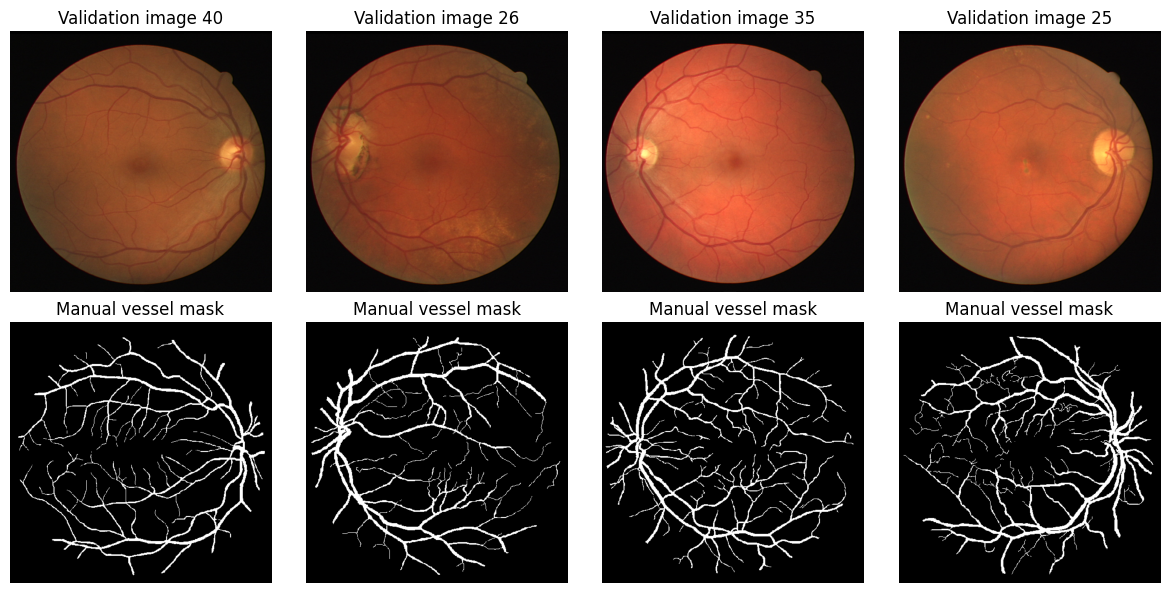

In [5]:
class RetinalVesselDataset(Dataset):
    def __init__(self, pairs, image_size=512):
        self.pairs = list(pairs)
        self.image_size = image_size

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        image_path, mask_path = self.pairs[index]
        with Image.open(image_path) as source_image, Image.open(mask_path) as source_mask:
            image = source_image.convert("RGB").resize(
                (self.image_size, self.image_size), Image.Resampling.BILINEAR
            )
            mask = source_mask.convert("L").resize(
                (self.image_size, self.image_size), Image.Resampling.NEAREST
            )
            image_array = np.array(image, dtype=np.float32) / 255.0
            mask_array = (np.array(mask, dtype=np.float32) / 255.0 > 0.5).astype(np.float32)
        return (torch.from_numpy(image_array).permute(2, 0, 1).contiguous(),
                torch.from_numpy(mask_array).unsqueeze(0))


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def make_loader(dataset, shuffle, seed):
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=2 if device.type == "cuda" else 0,
        pin_memory=device.type == "cuda", worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(seed)
    )


train_dataset = RetinalVesselDataset(train_pairs, IMG_SIZE)
val_dataset = RetinalVesselDataset(val_pairs, IMG_SIZE)
test_dataset = RetinalVesselDataset(test_pairs, IMG_SIZE) if test_evaluation_available else None
train_loader = make_loader(train_dataset, True, SEED)
val_loader = make_loader(val_dataset, False, SEED + 1)
test_loader = make_loader(test_dataset, False, SEED + 2) if test_dataset is not None else None

# Audit every prepared training/validation sample, not just the displayed example.
for dataset in (train_dataset, val_dataset):
    for image, mask in dataset:
        assert image.shape == (3, IMG_SIZE, IMG_SIZE)
        assert mask.shape == (1, IMG_SIZE, IMG_SIZE)
        assert image.dtype == mask.dtype == torch.float32
        assert torch.isfinite(image).all() and 0.0 <= float(image.min()) <= float(image.max()) <= 1.0
        assert torch.all((mask == 0) | (mask == 1))
print("Image/manual-mask pairing, 512x512 tensors, ranges, and binary masks verified.")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index in range(4):
    image, mask = val_dataset[index]
    axes[0, index].imshow(image.permute(1, 2, 0).numpy())
    axes[0, index].set_title(f"Validation image {get_image_id(val_pairs[index][0])}")
    axes[1, index].imshow(mask[0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[1, index].set_title("Manual vessel mask")
    axes[0, index].axis("off")
    axes[1, index].axis("off")
fig.tight_layout()
fig.savefig(results_dir / "input_pairs.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


In [6]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.bottleneck = DoubleConv(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        self.final_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final_conv(d1)

In [7]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs = probs.view(-1)
        targets = targets.view(-1)

        intersection = (probs * targets).sum()
        dice = (2.0 * intersection + self.smooth) / (probs.sum() + targets.sum() + self.smooth)

        return 1.0 - dice


class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()

    def forward(self, logits, targets):
        return self.bce(logits, targets) + self.dice(logits, targets)


In [8]:
METRIC_DEFINITIONS = {
    "scope": "all pixels of each resized 512x512 image; not an official native-resolution/FOV benchmark",
    "threshold_rule": "sigmoid(logits) > threshold, applied once; no threshold in the soft scores or loss",
    "global_dice": "2*TP/(2*TP+FP+FN), pooled across the entire evaluated split",
    "global_iou": "TP/(TP+FP+FN), pooled across the entire evaluated split",
    "mean_dice": "arithmetic mean of per-image thresholded Dice; each image has equal weight",
    "mean_iou": "arithmetic mean of per-image thresholded IoU; each image has equal weight",
    "soft_dice": "mean per-image soft Dice, using probabilities and smooth=1e-6",
    "soft_global_dice": "soft Dice pooled over all images/pixels; the loss pools within each training batch",
    "empty_masks": "binary Dice/IoU=1 if both masks are empty, 0 if exactly one is empty; same rule globally",
    "soft_empty_masks": "use smooth/(sum(probabilities)+smooth), without thresholding or overriding the soft formula",
    "missing_subsets": "None -> JSON null / empty CSV cell if no positive or no empty images",
    "epoch_loss": "sample-weighted mean of the original BCEWithLogits + batch-global soft Dice objective",
    "checkpoint_selection": "highest validation global Dice at fixed threshold 0.5; earliest epoch wins ties",
    "threshold_selection": "validation only on the selected checkpoint; original grid 0.10..0.85 step 0.05; earliest threshold wins ties",
}


def segmentation_metrics(probabilities, targets, threshold=0.5, smooth=1e-6):
    probabilities = torch.as_tensor(probabilities).detach().to(device="cpu", dtype=torch.float64)
    targets = torch.as_tensor(targets).detach().to(device="cpu", dtype=torch.float64)
    if probabilities.shape != targets.shape or targets.ndim != 4 or targets.shape[1] != 1 or targets.numel() == 0:
        raise ValueError("Expected matching nonempty probabilities and binary targets of shape (N, 1, H, W).")
    if not torch.isfinite(probabilities).all() or torch.any((probabilities < 0) | (probabilities > 1)):
        raise ValueError("Probabilities must be finite and in [0, 1].")
    if not torch.isfinite(targets).all() or not torch.all((targets == 0) | (targets == 1)):
        raise ValueError("Ground-truth masks must be finite and binary.")
    if not np.isfinite(threshold) or not 0 <= threshold <= 1 or not np.isfinite(smooth) or smooth <= 0:
        raise ValueError("Invalid threshold or smoothing value.")

    probability = probabilities.flatten(1)
    true = targets.flatten(1).bool()
    predicted = probability > threshold
    intersection = (predicted & true).sum(1).double()
    true_sum = true.sum(1).double()
    predicted_sum = predicted.sum(1).double()
    denominator = true_sum + predicted_sum
    union = denominator - intersection
    per_image_dice = torch.ones_like(denominator)
    per_image_iou = torch.ones_like(union)
    nonempty = denominator > 0
    per_image_dice[nonempty] = 2.0 * intersection[nonempty] / denominator[nonempty]
    nonempty_union = union > 0
    per_image_iou[nonempty_union] = intersection[nonempty_union] / union[nonempty_union]

    soft_intersection = (probability * true).sum(1)
    probability_sum = probability.sum(1)
    soft_denominator = true_sum + probability_sum
    soft_per_image = (2.0 * soft_intersection + smooth) / (soft_denominator + smooth)
    positive = true_sum > 0
    empty = ~positive

    def subset_mean(values, selector):
        return float(values[selector].mean()) if bool(selector.any()) else None

    tp = int(intersection.sum())
    fp = int(predicted_sum.sum()) - tp
    fn = int(true_sum.sum()) - tp
    tn = targets.numel() - tp - fp - fn
    global_denominator = 2 * tp + fp + fn
    global_union = tp + fp + fn
    return {
        "threshold": float(threshold),
        "n_images": len(targets), "n_positive_images": int(positive.sum()), "n_empty_images": int(empty.sum()),
        "global_dice": 2.0 * tp / global_denominator if global_denominator else 1.0,
        "global_iou": tp / global_union if global_union else 1.0,
        "mean_dice": float(per_image_dice.mean()), "mean_iou": float(per_image_iou.mean()),
        "mean_dice_positive": subset_mean(per_image_dice, positive),
        "mean_iou_positive": subset_mean(per_image_iou, positive),
        "mean_dice_empty": subset_mean(per_image_dice, empty),
        "soft_dice": float(soft_per_image.mean()),
        "soft_dice_positive": subset_mean(soft_per_image, positive),
        "soft_dice_empty": subset_mean(soft_per_image, empty),
        "soft_global_dice": float((2.0 * soft_intersection.sum() + smooth) / (soft_denominator.sum() + smooth)),
        "empty_false_positive_rate": float((predicted_sum[empty] > 0).double().mean()) if bool(empty.any()) else None,
        "precision": tp / (tp + fp) if tp + fp else None,
        "recall_sensitivity": tp / (tp + fn) if tp + fn else None,
        "specificity": tn / (tn + fp) if tn + fp else None,
        "pixel_accuracy": (tp + tn) / targets.numel(),
        "tp_pixels": tp, "fp_pixels": fp, "fn_pixels": fn, "tn_pixels": tn,
    }


def evaluate_model(model, loader, criterion, device, threshold=0.5):
    if loader is None or len(loader.dataset) == 0:
        raise ValueError("Evaluation requires a nonempty labeled dataset.")
    model.eval()
    total_loss, total_images = 0.0, 0
    probability_batches, target_batches = [], []
    with torch.inference_mode():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            if logits.shape != targets.shape:
                raise ValueError("Logit/target shape mismatch.")
            loss = criterion(logits, targets)
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite evaluation loss.")
            total_loss += float(loss) * len(images)
            total_images += len(images)
            probability_batches.append(torch.sigmoid(logits).cpu().float())
            target_batches.append(targets.cpu().float())
    probabilities, targets = torch.cat(probability_batches), torch.cat(target_batches)
    metrics = segmentation_metrics(probabilities, targets, threshold)
    metrics["loss"] = total_loss / total_images
    return metrics, probabilities, targets


def dataframe_records_for_json(frame):
    # A DataFrame can convert missing numeric values to NaN; strict JSON uses null.
    return frame.astype(object).where(pd.notna(frame), None).to_dict(orient="records")

METRIC_DEFINITIONS.update({
    "precision": "TP/(TP+FP); undefined denominator -> None",
    "recall_sensitivity": "TP/(TP+FN); undefined denominator -> None",
    "specificity": "TN/(TN+FP); undefined denominator -> None",
    "pixel_accuracy": "(TP+TN)/(TP+FP+FN+TN), over the same full-image pixel scope as Dice/IoU",
})


In [9]:
def verify_metric_and_loss_formulas():
    """Small known-answer masks only: no model fitting or optimizer step."""
    def masks(rows):
        return torch.tensor(rows, dtype=torch.float32).reshape(-1, 1, 2, 2)

    empty, vessel = masks([[0, 0, 0, 0]]), masks([[1, 0, 0, 0]])
    disjoint = masks([[0, 1, 0, 0]])
    for target in (empty, vessel):
        correct = segmentation_metrics(target, target)
        for name in ("global_dice", "global_iou", "mean_dice", "mean_iou", "soft_dice"):
            np.testing.assert_allclose(correct[name], 1.0)
    assert segmentation_metrics(empty, empty)["mean_dice_positive"] is None
    assert segmentation_metrics(vessel, vessel)["empty_false_positive_rate"] is None
    for probability, target in ((vessel, empty), (empty, vessel), (disjoint, vessel)):
        wrong = segmentation_metrics(probability, target)
        for name in ("global_dice", "global_iou", "mean_dice", "mean_iou"):
            assert wrong[name] == 0.0

    different_sizes = segmentation_metrics(
        masks([[1, 1, 1, 1], [0, 0, 0, 0]]), masks([[1, 1, 1, 1], [1, 0, 0, 0]])
    )
    np.testing.assert_allclose(different_sizes["global_dice"], 8 / 9)
    np.testing.assert_allclose(different_sizes["global_iou"], 4 / 5)
    np.testing.assert_allclose(different_sizes["mean_dice"], 0.5)
    assert different_sizes["global_dice"] != different_sizes["mean_dice"]

    # Sub-batch Dice averages are not a dataset Global Dice; pooling counts is.
    probability = masks([[1, 1, 1, 1], [0, 0, 0, 0], [1, 0, 0, 0]])
    target = masks([[1, 1, 1, 1], [1, 0, 0, 0], [1, 0, 0, 0]])
    full = segmentation_metrics(probability, target)
    for batch_size in (1, 2, 3):
        parts = [segmentation_metrics(probability[start:start + batch_size], target[start:start + batch_size])
                 for start in range(0, 3, batch_size)]
        tp = sum(part["tp_pixels"] for part in parts)
        fp = sum(part["fp_pixels"] for part in parts)
        fn = sum(part["fn_pixels"] for part in parts)
        np.testing.assert_allclose(2 * tp / (2 * tp + fp + fn), full["global_dice"])
        np.testing.assert_allclose(sum(part["mean_dice"] * part["n_images"] for part in parts) / 3, full["mean_dice"])

    fractional = segmentation_metrics(masks([[0.75, 0.25, 0, 0]]), vessel)
    np.testing.assert_allclose(fractional["soft_dice"], (1.5 + 1e-6) / (2 + 1e-6))
    assert fractional["global_dice"] == 1.0
    assert segmentation_metrics(masks([[0.50001, 0.5, 0, 0]]), vessel)["global_dice"] == 1.0
    soft_empty = segmentation_metrics(empty + 0.01, empty)
    np.testing.assert_allclose(soft_empty["soft_dice"], 1e-6 / (0.04 + 1e-6), rtol=1e-6)
    assert soft_empty["mean_dice"] == 1.0

    # The unchanged loss expects logits, not already-sigmoided probabilities.
    logits = torch.tensor([np.log(3), -np.log(3)], dtype=torch.float32).reshape(1, 1, 1, 2).requires_grad_()
    binary_target = torch.tensor([1.0, 0.0]).reshape(1, 1, 1, 2)
    loss = BCEDiceLoss()(logits, binary_target)
    expected_loss = -np.log(0.75) + 1 - (1.5 + 1e-6) / (2 + 1e-6)
    np.testing.assert_allclose(float(loss.detach()), expected_loss, rtol=1e-6)
    loss.backward()
    assert torch.isfinite(logits.grad).all()
    json.dumps(segmentation_metrics(empty, empty), allow_nan=False)
    for invalid in (torch.full_like(vessel, float("nan")), torch.full_like(vessel, 1.1)):
        try:
            segmentation_metrics(invalid, vessel)
        except ValueError:
            pass
        else:
            raise AssertionError("Invalid probabilities were accepted.")
    print("Dice/IoU, global vs mean, empty masks, batch partitioning, threshold, loss, and gradient checks passed.")


verify_metric_and_loss_formulas()


Dice/IoU, global vs mean, empty masks, batch partitioning, threshold, loss, and gradient checks passed.


In [10]:
# Additional known-answer checks for the requested pixel classification metrics.
classification_truth = torch.tensor([1, 1, 0, 0], dtype=torch.float32).reshape(1, 1, 2, 2)
classification_prediction = torch.tensor([1, 0, 1, 0], dtype=torch.float32).reshape(1, 1, 2, 2)
classification_metrics = segmentation_metrics(classification_prediction, classification_truth)
for name in ("precision", "recall_sensitivity", "specificity", "pixel_accuracy", "global_dice"):
    np.testing.assert_allclose(classification_metrics[name], 0.5)
np.testing.assert_allclose(classification_metrics["global_iou"], 1 / 3)
empty_metrics = segmentation_metrics(torch.zeros_like(classification_truth), torch.zeros_like(classification_truth))
assert empty_metrics["precision"] is None and empty_metrics["recall_sensitivity"] is None
assert empty_metrics["specificity"] == empty_metrics["pixel_accuracy"] == 1.0
positive_metrics = segmentation_metrics(torch.ones_like(classification_truth), torch.ones_like(classification_truth))
assert positive_metrics["specificity"] is None
json.dumps([classification_metrics, empty_metrics, positive_metrics], allow_nan=False)
del classification_truth, classification_prediction, classification_metrics, empty_metrics, positive_metrics
print("Precision, recall, specificity, accuracy, and undefined-denominator checks passed.")


Precision, recall, specificity, accuracy, and undefined-denominator checks passed.


In [11]:
model = UNet(in_channels=3, out_channels=1).to(device)
criterion = BCEDiceLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Shape check in eval mode avoids changing BatchNorm buffers before training.
probe_image, probe_target = val_dataset[0]
model.eval()
with torch.inference_mode():
    probe_logits = model(probe_image.unsqueeze(0).to(device))
    assert probe_logits.shape == (1, 1, IMG_SIZE, IMG_SIZE)
    assert torch.isfinite(probe_logits).all()
    assert torch.isfinite(criterion(probe_logits, probe_target.unsqueeze(0).to(device)))
model.train()
del probe_logits
print("U-Net input (N,3,512,512) -> logits (N,1,512,512); BCEWithLogits + Dice loss verified.")
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))


U-Net input (N,3,512,512) -> logits (N,1,512,512); BCEWithLogits + Dice loss verified.
Trainable parameters: 31043521


In [12]:
def read_checkpoint_summary(checkpoint_path, explicit_summary=""):
    if explicit_summary:
        path = Path(explicit_summary).expanduser()
        if not path.is_file():
            raise FileNotFoundError(path)
        return json.loads(path.read_text(encoding="utf-8")), path
    candidates = [checkpoint_path.parent / "checkpoint_metadata.json",
                  checkpoint_path.parent.parent / "results" / "results_summary.json",
                  checkpoint_path.parent.parent / "results" / "metrics.json"]
    for path in candidates:
        if path.is_file():
            return json.loads(path.read_text(encoding="utf-8")), path
    return {}, None


def checkpoint_configuration_matches(metadata):
    configuration = metadata.get("configuration", {})
    expected = {"seed": SEED, "image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
                "epochs": EPOCHS, "learning_rate": LEARNING_RATE}
    if any(configuration.get(key) != value for key, value in expected.items()):
        return False
    manifest = metadata.get("dataset", {}).get("split_manifest", [])
    saved_train_ids = {str(row["image_id"]) for row in manifest if row.get("split") == "train"}
    saved_val_ids = {str(row["image_id"]) for row in manifest if row.get("split") == "validation"}
    return saved_train_ids == train_ids and saved_val_ids == val_ids


checkpoint_source = None
checkpoint_source_summary, checkpoint_source_summary_path = {}, None
if EXISTING_CHECKPOINT_PATH:
    checkpoint_source = Path(EXISTING_CHECKPOINT_PATH).expanduser().resolve()
    if not checkpoint_source.is_file():
        raise FileNotFoundError(f"Configured best state_dict is missing: {checkpoint_source}")
    checkpoint_source_summary, checkpoint_source_summary_path = read_checkpoint_summary(
        checkpoint_source, EXISTING_RUN_SUMMARY_PATH
    )
    if checkpoint_source_summary and not checkpoint_configuration_matches(checkpoint_source_summary):
        raise ValueError("Checkpoint metadata does not match the original configuration and 16/4 split.")
elif REUSE_COMPATIBLE_CHECKPOINT:
    search_roots = [project_dir / "runs"]
    if PERSIST_CHECKPOINT_TO_DRIVE:
        search_roots.append(Path(DRIVE_BACKUP_DIRECTORY))
    candidates = [path for root in search_roots if root.is_dir()
                  for path in root.rglob("best_unet_retinal_vessel_segmentation.pth")
                  if path.resolve() != BEST_MODEL_PATH.resolve()]
    for candidate in sorted(candidates, key=lambda path: path.stat().st_mtime, reverse=True):
        metadata, metadata_path = read_checkpoint_summary(candidate)
        if checkpoint_configuration_matches(metadata):
            checkpoint_source, checkpoint_source_summary = candidate, metadata
            checkpoint_source_summary_path = metadata_path
            break

reuse_checkpoint = checkpoint_source is not None
training_was_run = False
history_origin = None
checkpoint_sample = val_dataset[0][0].unsqueeze(0).to(device)
if reuse_checkpoint:
    state_dict = torch.load(checkpoint_source, map_location="cpu", weights_only=True)
    model.load_state_dict(state_dict, strict=True)
    del state_dict
    shutil.copy2(checkpoint_source, BEST_MODEL_PATH)
    model.eval()
    with torch.inference_mode():
        best_reference_probability = torch.sigmoid(model(checkpoint_sample)).cpu().clone()
    best_epoch_metrics, _, _ = evaluate_model(model, val_loader, criterion, device, EPOCH_METRIC_THRESHOLD)
    best_epoch = checkpoint_source_summary.get("best_checkpoint", {}).get("epoch")
    best_checkpoint_score = best_epoch_metrics["global_dice"]
    training_seconds = 0.0
    history_rows = []
    history_df = pd.DataFrame()
    history_candidates = [checkpoint_source.parent.parent / "results" / "training_history.csv"]
    if checkpoint_source_summary_path is not None:
        history_candidates.append(checkpoint_source_summary_path.parent / "training_history.csv")
    for history_path in history_candidates:
        if history_path.is_file():
            history_df = pd.read_csv(history_path)
            required_columns = {"epoch", "train_loss", "val_loss", "val_global_dice_t050",
                                "val_global_iou_t050", "val_mean_dice_t050"}
            if not required_columns.issubset(history_df.columns):
                raise ValueError("Saved training history has incompatible columns.")
            history_rows = dataframe_records_for_json(history_df)
            history_origin = str(history_path)
            shutil.copy2(history_path, results_dir / "training_history.csv")
            break
    print("Reusing the selected best checkpoint; no new training:", checkpoint_source)
    if best_epoch is None:
        print("Original epoch metadata is unavailable; no epoch number is invented.")
else:
    if not TRAIN_IF_CHECKPOINT_MISSING:
        raise FileNotFoundError(
            "No compatible trained checkpoint found. Set EXISTING_CHECKPOINT_PATH or enable the preserved 15-epoch training flow in Colab."
        )
    print("No trained state_dict found. The next cell will run the original 15 epochs when you execute it in Colab.")


No trained state_dict found. The next cell will run the original 15 epochs when you execute it in Colab.


In [13]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    loss_sum, image_count = 0.0, 0
    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()
        logits = model(images)
        if logits.shape != targets.shape:
            raise ValueError("Logit/target shape mismatch during training.")
        loss = criterion(logits, targets)
        if not torch.isfinite(loss):
            raise FloatingPointError("Nonfinite training loss.")
        loss.backward()
        optimizer.step()
        loss_sum += float(loss.detach()) * len(images)
        image_count += len(images)
    if image_count == 0:
        raise ValueError("Training dataset is empty.")
    return loss_sum / image_count


if reuse_checkpoint:
    print("Training skipped: using the existing selected checkpoint.")
else:
    training_was_run = True
    history_rows = []
    best_epoch = None
    best_checkpoint_score = -1.0
    best_epoch_metrics = None
    best_reference_probability = None
    checkpoint_sample = val_dataset[0][0].unsqueeze(0).to(device)
    training_start = time.perf_counter()

    # This is the only long training cell: the original 15 epochs, batch size 2, Adam 1e-4.
    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        epoch_validation, _, _ = evaluate_model(model, val_loader, criterion, device, EPOCH_METRIC_THRESHOLD)
        improved = epoch_validation["global_dice"] > best_checkpoint_score
        if improved:
            best_checkpoint_score = epoch_validation["global_dice"]
            best_epoch = epoch
            best_epoch_metrics = dict(epoch_validation)
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            with torch.inference_mode():
                best_reference_probability = torch.sigmoid(model(checkpoint_sample)).cpu().clone()

        history_rows.append({
            "epoch": epoch, "train_loss": train_loss, "val_loss": epoch_validation["loss"],
            "val_global_dice_t050": epoch_validation["global_dice"],
            "val_global_iou_t050": epoch_validation["global_iou"],
            "val_mean_dice_t050": epoch_validation["mean_dice"],
            "val_mean_iou_t050": epoch_validation["mean_iou"],
            "val_soft_dice": epoch_validation["soft_dice"],
            "learning_rate": optimizer.param_groups[0]["lr"],
            "epoch_seconds": time.perf_counter() - epoch_start,
        })
        history_df = pd.DataFrame(history_rows)
        history_df.to_csv(results_dir / "training_history.csv", index=False)
        print(
            f"Epoch [{epoch:02d}/{EPOCHS}] | Train loss {train_loss:.4f} | Val loss {epoch_validation['loss']:.4f} | "
            f"Val Global Dice {epoch_validation['global_dice']:.4f} | Val Global IoU {epoch_validation['global_iou']:.4f} | "
            f"Val Mean Dice {epoch_validation['mean_dice']:.4f}" + (" | saved best" if improved else "")
        )

    training_seconds = time.perf_counter() - training_start
    assert BEST_MODEL_PATH.is_file() and best_epoch is not None
    print(f"Training complete in {training_seconds / 60:.2f} minutes; best validation checkpoint: epoch {best_epoch}.")


Epoch [01/15] | Train loss 1.3382 | Val loss 1.4826 | Val Global Dice 0.0000 | Val Global IoU 0.0000 | Val Mean Dice 0.0000 | saved best
Epoch [02/15] | Train loss 1.2090 | Val loss 1.4498 | Val Global Dice 0.0000 | Val Global IoU 0.0000 | Val Mean Dice 0.0000
Epoch [03/15] | Train loss 1.1226 | Val loss 1.3930 | Val Global Dice 0.0000 | Val Global IoU 0.0000 | Val Mean Dice 0.0000
Epoch [04/15] | Train loss 1.0570 | Val loss 1.3297 | Val Global Dice 0.0039 | Val Global IoU 0.0019 | Val Mean Dice 0.0038 | saved best
Epoch [05/15] | Train loss 1.0242 | Val loss 1.2592 | Val Global Dice 0.0802 | Val Global IoU 0.0418 | Val Mean Dice 0.0721 | saved best
Epoch [06/15] | Train loss 1.0013 | Val loss 1.1839 | Val Global Dice 0.2632 | Val Global IoU 0.1516 | Val Mean Dice 0.2221 | saved best
Epoch [07/15] | Train loss 0.9801 | Val loss 1.0978 | Val Global Dice 0.5025 | Val Global IoU 0.3356 | Val Mean Dice 0.4939 | saved best
Epoch [08/15] | Train loss 0.9609 | Val loss 1.0512 | Val Global Di

In [14]:
# Load the selected state_dict into both the working model and a fresh U-Net.
# weights_only=True is appropriate for a state_dict of tensors.
saved_state_dict = torch.load(BEST_MODEL_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(saved_state_dict, strict=True)
reloaded_model = UNet(in_channels=3, out_channels=1).to(device)
reloaded_model.load_state_dict(saved_state_dict, strict=True)
model.eval()
reloaded_model.eval()
with torch.inference_mode():
    selected_probability = torch.sigmoid(model(checkpoint_sample)).cpu()
    reloaded_probability = torch.sigmoid(reloaded_model(checkpoint_sample)).cpu()
assert torch.isfinite(selected_probability).all() and torch.isfinite(reloaded_probability).all()
torch.testing.assert_close(selected_probability, best_reference_probability, rtol=1e-5, atol=1e-6)
torch.testing.assert_close(selected_probability, reloaded_probability, rtol=1e-5, atol=1e-6)
reload_max_absolute_difference = float((selected_probability - reloaded_probability).abs().max())
print("Best-checkpoint state_dict reload check passed. Maximum probability difference:", reload_max_absolute_difference)
del reloaded_model, saved_state_dict

# All following evaluation and threshold selection uses the selected checkpoint.
selected_validation_fixed, val_probabilities, val_targets = evaluate_model(
    model, val_loader, criterion, device, EPOCH_METRIC_THRESHOLD
)
np.testing.assert_allclose(selected_validation_fixed["global_dice"], best_epoch_metrics["global_dice"], rtol=1e-6, atol=1e-8)


Best-checkpoint state_dict reload check passed. Maximum probability difference: 0.0


In [15]:
# The original threshold grid, computed on cached VALIDATION predictions only.
thresholds = np.round(np.arange(0.1, 0.9, 0.05), 2)
threshold_df = pd.DataFrame([
    segmentation_metrics(val_probabilities, val_targets, float(threshold)) for threshold in thresholds
])
best_threshold_row = threshold_df.sort_values(
    ["global_dice", "threshold"], ascending=[False, True], kind="stable"
).iloc[0]
best_threshold = float(best_threshold_row["threshold"])
assert best_threshold in thresholds
validation_metrics = segmentation_metrics(val_probabilities, val_targets, best_threshold)
validation_metrics["loss"] = selected_validation_fixed["loss"]
validation_results_df = pd.DataFrame.from_dict(validation_metrics, orient="index", columns=["value"])
print(f"Validation-selected threshold: {best_threshold:.2f} | checkpoint epoch: {best_epoch}")
display(threshold_df[["threshold", "global_dice", "global_iou", "mean_dice", "mean_iou"]])
print("Validation metrics: used for model/threshold selection, not an independent test estimate.")
display(validation_results_df)

test_metrics = None
test_probabilities = None
test_targets = None
if test_evaluation_available:
    # Test labels are accessed by the evaluator only after checkpoint/threshold selection.
    test_metrics, test_probabilities, test_targets = evaluate_model(
        model, test_loader, criterion, device, best_threshold
    )
    assert test_metrics["threshold"] == validation_metrics["threshold"]
    print("Independent local test metrics (full 512x512 images; validation-selected threshold):")
    display(pd.DataFrame.from_dict(test_metrics, orient="index", columns=["value"]))
else:
    print("Independent test evaluation skipped:", test_status["reason"])


Validation-selected threshold: 0.50 | checkpoint epoch: 15


,threshold,global_dice,global_iou,mean_dice,mean_iou
0,0.10,0.158102,0.085837,0.158019,0.085837
1,0.15,0.213924,0.119773,0.213768,0.119765
2,0.20,0.293676,0.172110,0.294411,0.172964
3,0.25,0.567425,0.396087,0.570596,0.400051
4,0.30,0.677746,0.512568,0.678895,0.514549
5,0.35,0.716852,0.558666,0.716800,0.558955
6,0.40,0.728595,0.573062,0.727724,0.572203
7,0.45,0.732523,0.577939,0.730920,0.576202
8,0.50,0.732961,0.578483,0.730824,0.576232
9,0.55,0.731046,0.576101,0.728321,0.573439


Validation metrics: used for model/threshold selection, not an independent test estimate.


,value
threshold,0.500000
n_images,4.000000
n_positive_images,4.000000
n_empty_images,0.000000
global_dice,0.732961
global_iou,0.578483
mean_dice,0.730824
mean_iou,0.576232
mean_dice_positive,0.730824
mean_iou_positive,0.576232


Independent test evaluation skipped: No verified manual test-vessel annotations are available in this run. Official references are hidden. Local test metrics remain unavailable; no proxy labels are generated.


In [16]:
class OfficialTestImagesOnly(Dataset):
    """Image-only loader: no fabricated targets when vessel labels are absent."""
    def __init__(self, paths):
        self.paths = list(paths)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as source:
            image = source.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
            image_array = np.array(image, dtype=np.float32) / 255.0
        return torch.from_numpy(image_array).permute(2, 0, 1).contiguous()


if not test_evaluation_available:
    image_only_test_dataset = OfficialTestImagesOnly(official_test_images)
    image_only_test_loader = DataLoader(image_only_test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                       num_workers=0, pin_memory=device.type == "cuda")
    model.eval()
    test_probability_batches = []
    with torch.inference_mode():
        for images in image_only_test_loader:
            probabilities = torch.sigmoid(model(images.to(device))).cpu().float()
            if not torch.isfinite(probabilities).all():
                raise FloatingPointError("Nonfinite test probabilities.")
            test_probability_batches.append(probabilities)
    test_probabilities = torch.cat(test_probability_batches)
assert test_probabilities.shape == (20, 1, IMG_SIZE, IMG_SIZE)
assert {get_image_id(path) for path in official_test_images} == {f"{index:02d}" for index in range(1, 21)}

# Prepare an optional submission package; nothing is uploaded to an external service.
# The official server scores native-size predictions inside the FOV; local validation
# and any local labeled-test metrics above remain on the full 512x512 image grid.
submission_dir = run_dir / "official_test_submission"
submission_dir.mkdir(exist_ok=True)
for index, image_path in enumerate(official_test_images):
    with Image.open(image_path) as original_image:
        native_size = original_image.size
    binary = (test_probabilities[index, 0].numpy() > best_threshold).astype(np.uint8) * 255
    native_prediction = Image.fromarray(binary).resize(native_size, Image.Resampling.NEAREST)
    native_prediction.save(submission_dir / f"{int(get_image_id(image_path))}.png")
submission_zip_path = run_dir / "official_test_predictions.zip"
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in sorted(submission_dir.glob("*.png"), key=lambda path: int(path.stem)):
        archive.write(path, path.name)
print("All 20 real test predictions generated with the validation-selected threshold.")
print("Optional official-server submission ZIP (not submitted):", submission_zip_path)


All 20 real test predictions generated with the validation-selected threshold.
Optional official-server submission ZIP (not submitted): /content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z/official_test_predictions.zip


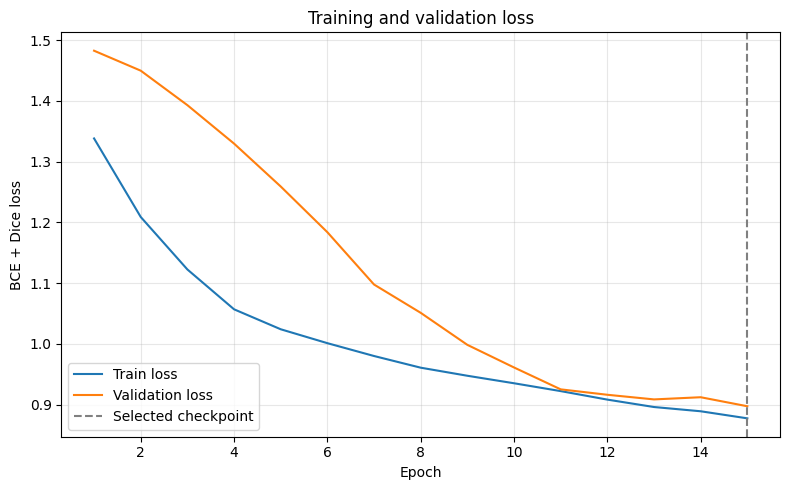

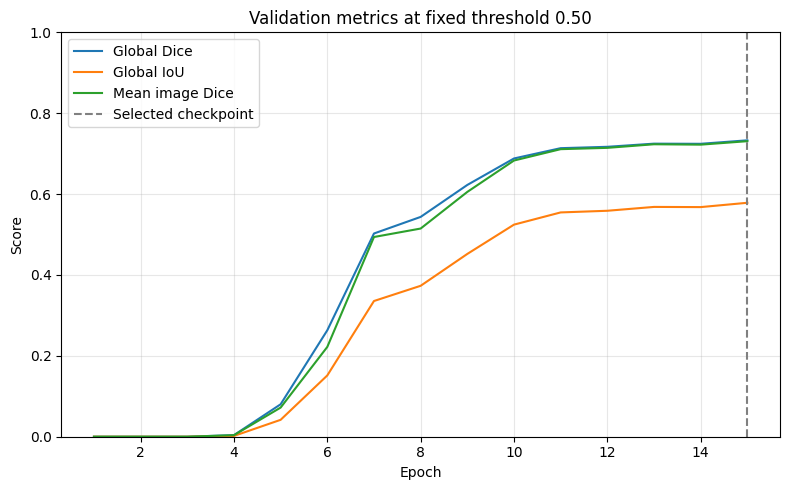

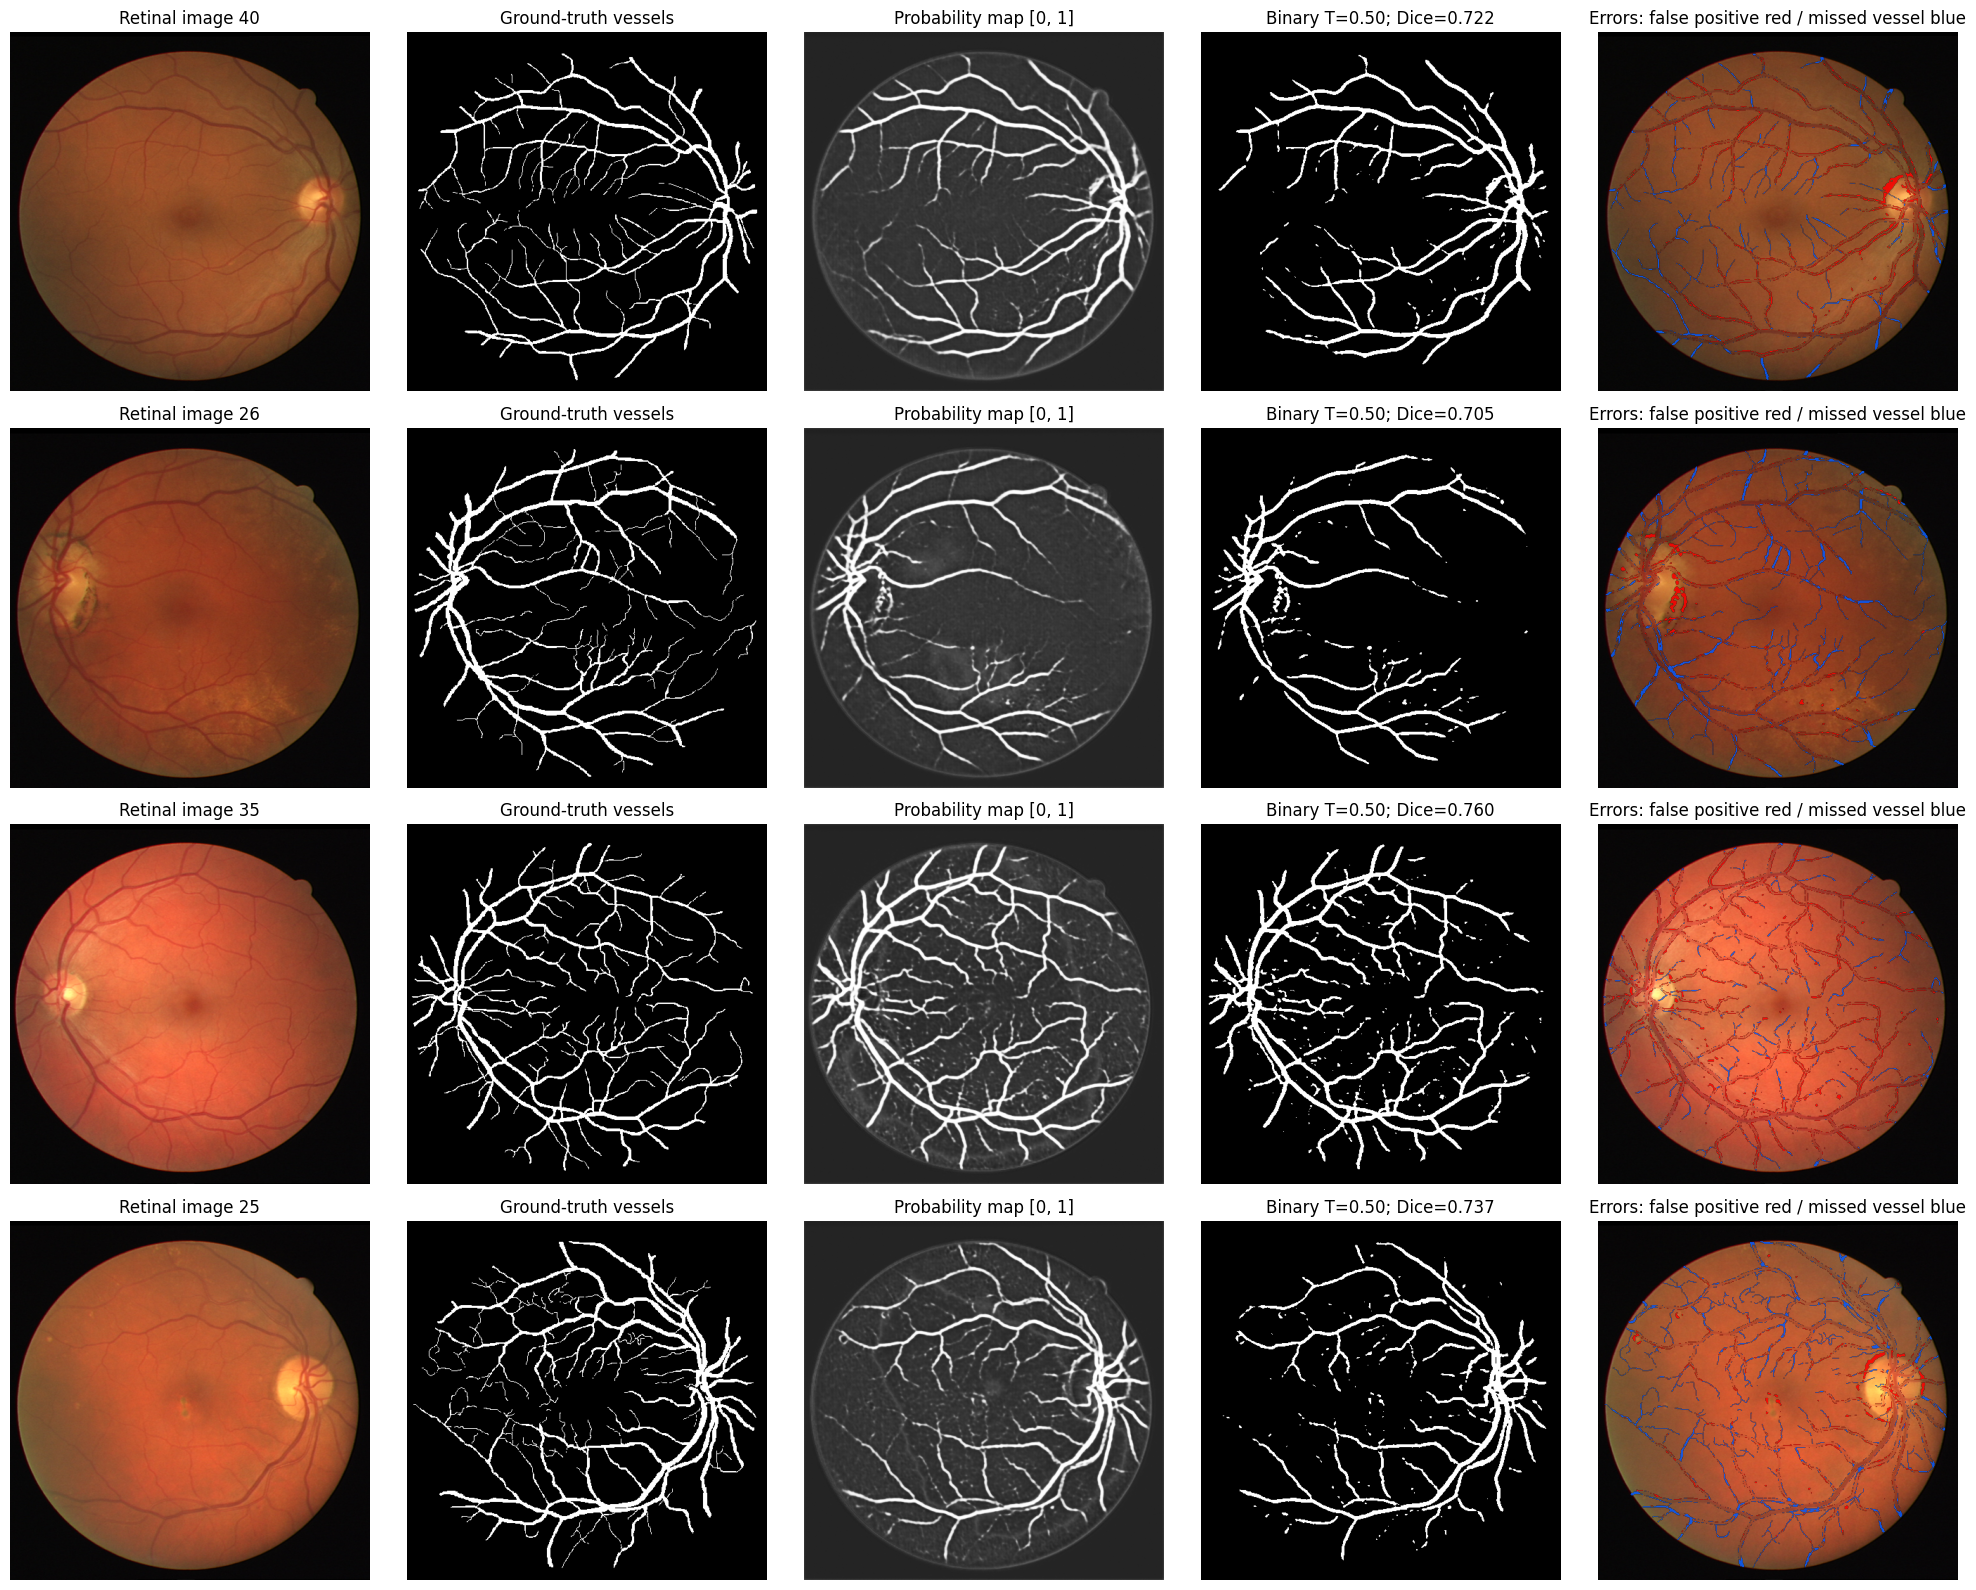

In [17]:
if not history_df.empty:
    fig, axes = plt.subplots(figsize=(8, 5))
    axes.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
    axes.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
    if best_epoch is not None:
        axes.axvline(best_epoch, color="gray", linestyle="--", label="Selected checkpoint")
    axes.set(xlabel="Epoch", ylabel="BCE + Dice loss", title="Training and validation loss")
    axes.grid(alpha=0.3)
    axes.legend()
    fig.tight_layout()
    fig.savefig(results_dir / "training_validation_loss.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    fig, axes = plt.subplots(figsize=(8, 5))
    for key, label in (("val_global_dice_t050", "Global Dice"), ("val_global_iou_t050", "Global IoU"),
                       ("val_mean_dice_t050", "Mean image Dice")):
        axes.plot(history_df["epoch"], history_df[key], label=label)
    axes.set(xlabel="Epoch", ylabel="Score", title="Validation metrics at fixed threshold 0.50", ylim=(0, 1))
    if best_epoch is not None:
        axes.axvline(best_epoch, color="gray", linestyle="--", label="Selected checkpoint")
    axes.grid(alpha=0.3)
    axes.legend()
    fig.tight_layout()
    fig.savefig(results_dir / "validation_dice_iou.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

else:
    print("Original training history is unavailable for this imported checkpoint; no training curve is invented.")

# Show all four validation images in their fixed split order, including errors.
sample_count = len(val_dataset)
fig, axes = plt.subplots(sample_count, 5, figsize=(20, 4 * sample_count), squeeze=False)
per_image_rows = []
for index in range(sample_count):
    image, target = val_dataset[index]
    torch.testing.assert_close(target, val_targets[index])
    image_array = image.permute(1, 2, 0).numpy()
    true_mask = target[0].numpy().astype(bool)
    probability = val_probabilities[index, 0].numpy()
    predicted_mask = probability > best_threshold
    image_metrics = segmentation_metrics(val_probabilities[index:index + 1], val_targets[index:index + 1], best_threshold)
    image_id = get_image_id(val_pairs[index][0])
    per_image_rows.append({"image_id": image_id, **image_metrics})
    errors = np.zeros((*true_mask.shape, 4), dtype=np.float32)
    errors[predicted_mask & ~true_mask] = [1, 0, 0, 0.85]
    errors[true_mask & ~predicted_mask] = [0, 0.35, 1, 0.85]
    axes[index, 0].imshow(image_array)
    axes[index, 0].set_title(f"Retinal image {image_id}")
    axes[index, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
    axes[index, 1].set_title("Ground-truth vessels")
    axes[index, 2].imshow(probability, cmap="gray", vmin=0, vmax=1)
    axes[index, 2].set_title("Probability map [0, 1]")
    axes[index, 3].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axes[index, 3].set_title(f"Binary T={best_threshold:.2f}; Dice={image_metrics['mean_dice']:.3f}")
    axes[index, 4].imshow(image_array)
    axes[index, 4].imshow(errors)
    axes[index, 4].set_title("Errors: false positive red / missed vessel blue")
    for axis in axes[index]:
        axis.axis("off")
fig.tight_layout()
fig.savefig(sample_dir / "sample_predictions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
pd.DataFrame(per_image_rows).to_csv(results_dir / "validation_per_image_metrics.csv", index=False, na_rep="")


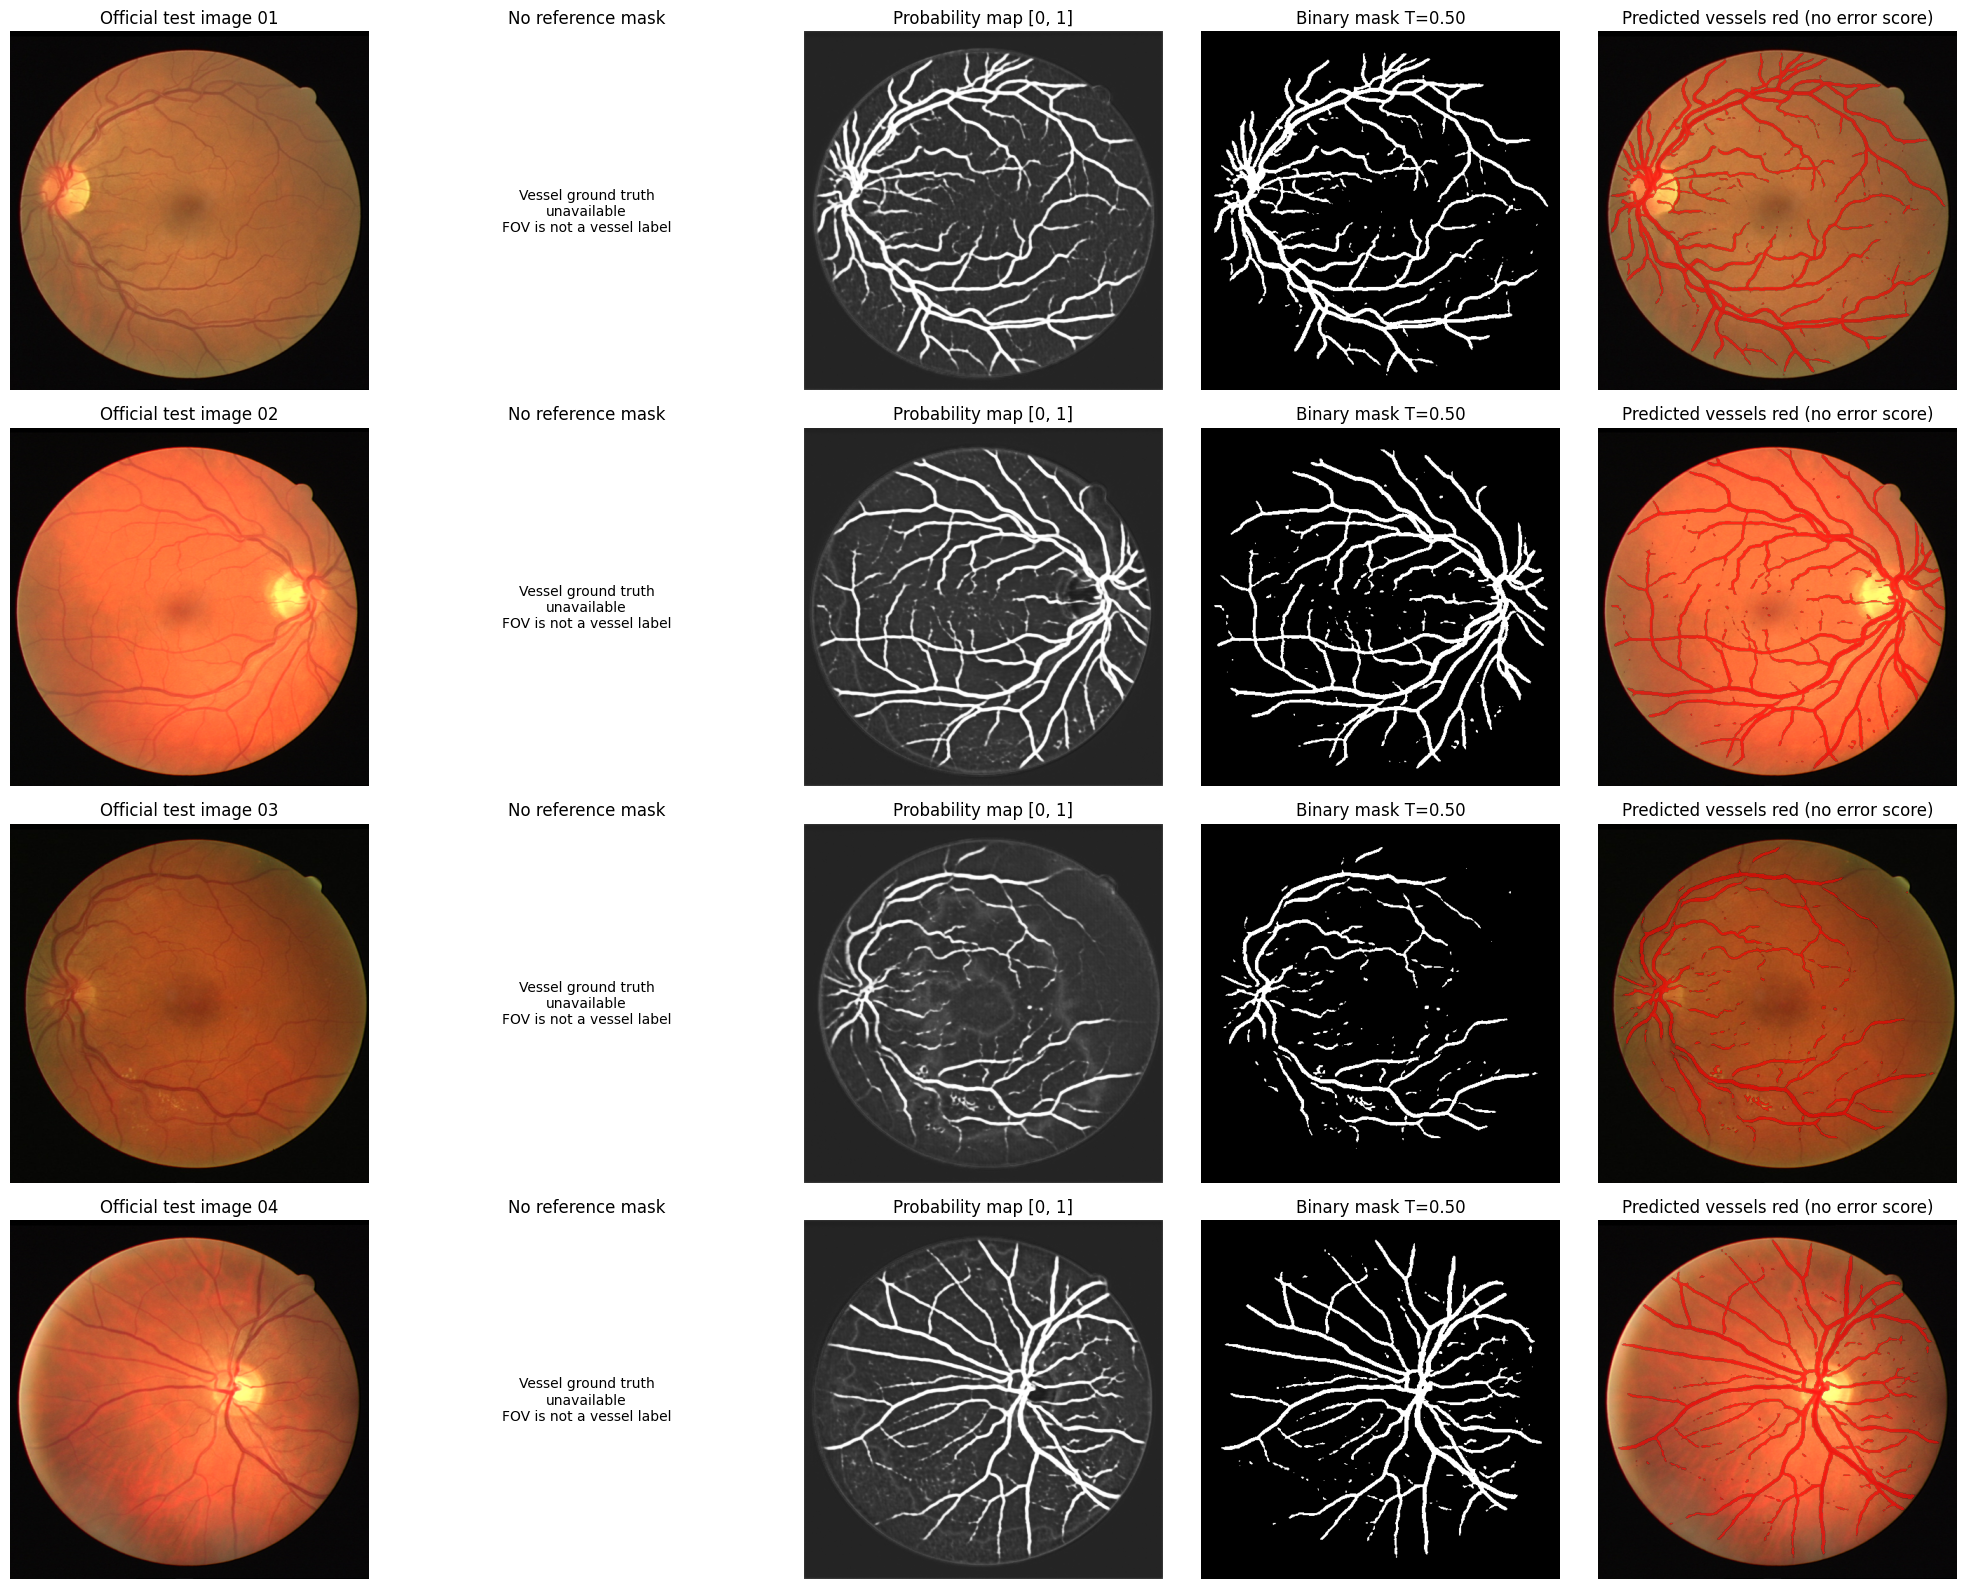

In [18]:
test_display_dataset = OfficialTestImagesOnly(official_test_images)
test_per_image_rows = []
requested_test_metric_names = ["global_dice", "global_iou", "mean_dice", "mean_iou",
                               "precision", "recall_sensitivity", "specificity", "pixel_accuracy"]
for index, image_path in enumerate(official_test_images):
    if test_evaluation_available:
        values = segmentation_metrics(test_probabilities[index:index + 1], test_targets[index:index + 1], best_threshold)
        test_per_image_rows.append({"image_id": get_image_id(image_path),
                                    "dice": values["mean_dice"], "iou": values["mean_iou"],
                                    **{key: values[key] for key in requested_test_metric_names[4:]}, "status": "computed"})
    else:
        test_per_image_rows.append({"image_id": get_image_id(image_path), "dice": None, "iou": None,
                                    **{key: None for key in requested_test_metric_names[4:]},
                                    "status": "unavailable_no_vessel_ground_truth"})
per_image_test_df = pd.DataFrame(test_per_image_rows)
per_image_test_df.to_csv(results_dir / "per_image_test_metrics.csv", index=False, na_rep="")

# Fixed first four IDs; no example selection based on performance.
fig, axes = plt.subplots(4, 5, figsize=(20, 16), squeeze=False)
for index in range(4):
    image_array = test_display_dataset[index].permute(1, 2, 0).numpy()
    probability = test_probabilities[index, 0].numpy()
    predicted = probability > best_threshold
    axes[index, 0].imshow(image_array)
    axes[index, 0].set_title(f"Official test image {get_image_id(official_test_images[index])}")
    if test_evaluation_available:
        true = test_targets[index, 0].numpy().astype(bool)
        axes[index, 1].imshow(true, cmap="gray", vmin=0, vmax=1)
        axes[index, 1].set_title("Manual vessel ground truth")
        overlay = np.zeros((*true.shape, 4), dtype=np.float32)
        overlay[predicted & ~true] = [1, 0, 0, 0.85]
        overlay[true & ~predicted] = [0, 0.35, 1, 0.85]
        overlay_title = "Errors: FP red / missed vessel blue"
    else:
        axes[index, 1].text(0.5, 0.5, "Vessel ground truth\nunavailable\nFOV is not a vessel label", ha="center", va="center", transform=axes[index, 1].transAxes)
        axes[index, 1].set_title("No reference mask")
        overlay = np.zeros((*predicted.shape, 4), dtype=np.float32)
        overlay[predicted] = [1, 0, 0, 0.6]
        overlay_title = "Predicted vessels red (no error score)"
    axes[index, 2].imshow(probability, cmap="gray", vmin=0, vmax=1)
    axes[index, 2].set_title("Probability map [0, 1]")
    axes[index, 3].imshow(predicted, cmap="gray", vmin=0, vmax=1)
    axes[index, 3].set_title(f"Binary mask T={best_threshold:.2f}")
    axes[index, 4].imshow(image_array)
    axes[index, 4].imshow(overlay)
    axes[index, 4].set_title(overlay_title)
    for axis in axes[index]:
        axis.axis("off")
fig.tight_layout()
fig.savefig(results_dir / "test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


In [19]:
threshold_df.to_csv(results_dir / "validation_threshold_results.csv", index=False, na_rep="")
validation_results_df.to_csv(results_dir / "validation_metrics.csv", index_label="metric", na_rep="")
with open(results_dir / "validation_metrics.json", "w", encoding="utf-8") as file:
    json.dump({"checkpoint_epoch": best_epoch, "metrics": validation_metrics,
               "definitions": METRIC_DEFINITIONS}, file, indent=2, allow_nan=False)
test_table = pd.DataFrame.from_dict(
    test_metrics if test_metrics is not None else {name: None for name in requested_test_metric_names},
    orient="index", columns=["value"]
)
test_table["status"] = "computed" if test_metrics is not None else "unavailable_no_vessel_ground_truth"
test_table.to_csv(results_dir / "test_metrics.csv", index_label="metric", na_rep="")
with open(results_dir / "test_metrics.json", "w", encoding="utf-8") as file:
    json.dump({"status": test_status, "metrics": test_metrics}, file, indent=2, allow_nan=False)

summary = {
    "source_notebook": SOURCE_NOTEBOOK,
    "framework": {"pytorch": str(torch.__version__), "numpy": np.__version__, "device": str(device)},
    "configuration": {"seed": SEED, "image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
                      "epochs": EPOCHS, "learning_rate": LEARNING_RATE, "optimizer": "Adam",
                      "loss": "original BCEWithLogitsLoss + batch-global soft Dice loss"},
    "dataset": {"handle": DATASET_HANDLE, "root": str(data_dir), "split_manifest": dataframe_records_for_json(split_manifest_df)},
    "best_checkpoint": {"epoch": best_epoch, "path": str(BEST_MODEL_PATH),
                        "selection_metric": "validation global Dice at threshold 0.5",
                        "validation_at_fixed_threshold": best_epoch_metrics},
    "last_epoch_metrics_at_fixed_threshold": history_rows[-1] if history_rows else None,
    "selected_checkpoint_validation_at_selected_threshold": validation_metrics,
    "threshold_selected_on": "validation", "selected_threshold": best_threshold,
    "validation_threshold_results": dataframe_records_for_json(threshold_df),
    "independent_test": {"status": test_status, "metrics": test_metrics},
    "metric_definitions": METRIC_DEFINITIONS,
    "limitations": ["Only four validation images; the same validation set selects checkpoint and threshold.",
                    "Full resized-image metrics are not official native-resolution/FOV benchmark results."],
    "reload_check": {"passed": True, "max_absolute_probability_difference": reload_max_absolute_difference},
    "training_seconds": training_seconds,
    "training_was_run_in_this_execution": training_was_run,
    "checkpoint_reused_from": str(checkpoint_source) if reuse_checkpoint else None,
    "training_history_origin": history_origin if reuse_checkpoint else "this execution",
    "test_annotation_provenance": test_annotation_provenance,
    "official_submission": {
        "path": str(submission_zip_path), "submitted": False,
        "scope": "nearest-neighbor-resized binary predictions at native size; official server evaluates inside FOV",
        "comparability": "official native/FOV scores are not the same scope as local full-512x512 validation/test scores"
    },
}
with open(results_dir / "results_summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2, allow_nan=False)
with open(results_dir / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=2, allow_nan=False)


# Keep the selected checkpoint portable with the actual validation-selected threshold
# and split/configuration metadata. No historical performance number is hard-coded.
checkpoint_metadata = {
    "configuration": summary["configuration"], "dataset": summary["dataset"],
    "best_checkpoint": summary["best_checkpoint"], "selected_threshold": best_threshold,
    "threshold_selected_on": "validation", "metric_definitions": METRIC_DEFINITIONS,
    "checkpoint_sha256": hashlib.sha256(BEST_MODEL_PATH.read_bytes()).hexdigest(),
    "source_notebook": SOURCE_NOTEBOOK,
}
checkpoint_metadata_path = model_dir / "checkpoint_metadata.json"
with open(checkpoint_metadata_path, "w", encoding="utf-8") as file:
    json.dump(checkpoint_metadata, file, indent=2, allow_nan=False)
if PERSIST_CHECKPOINT_TO_DRIVE:
    backup_run = Path(DRIVE_BACKUP_DIRECTORY) / run_dir.name
    (backup_run / "models").mkdir(parents=True, exist_ok=True)
    (backup_run / "results").mkdir(parents=True, exist_ok=True)
    for path in (BEST_MODEL_PATH, checkpoint_metadata_path):
        shutil.copy2(path, backup_run / "models" / path.name)
    for filename in ("training_history.csv", "results_summary.json"):
        path = results_dir / filename
        if path.is_file():
            shutil.copy2(path, backup_run / "results" / filename)
    print("Persistent checkpoint backup:", backup_run)

print("Validation results (computed from validation predictions):")
display(validation_results_df)
print("Test results (all 20 independent test images):")
display(test_table)
if test_metrics is None:
    print("Test values are unavailable because authentic vessel ground truth is missing; empty CSV values are not scores.")
print("Save the state_dict and checkpoint_metadata.json before ending a temporary Colab session.")

print("Run complete. Saved outputs:", run_dir)
for path in sorted(run_dir.rglob("*")):
    if path.is_file():
        print(path.relative_to(run_dir))
        display(FileLink(str(path)))

# Optional Colab download. Set True only when you want a ZIP of this completed run.
DOWNLOAD_RUN_ZIP = False
if DOWNLOAD_RUN_ZIP:
    archive_path = shutil.make_archive(str(run_dir), "zip", root_dir=run_dir)
    try:
        from google.colab import files
    except ImportError:
        display(FileLink(archive_path))
    else:
        files.download(archive_path)


Validation results (computed from validation predictions):


,value
threshold,0.500000
n_images,4.000000
n_positive_images,4.000000
n_empty_images,0.000000
global_dice,0.732961
global_iou,0.578483
mean_dice,0.730824
mean_iou,0.576232
mean_dice_positive,0.730824
mean_iou_positive,0.576232


Test results (all 20 independent test images):


,value,status
global_dice,None,unavailable_no_vessel_ground_truth
global_iou,None,unavailable_no_vessel_ground_truth
mean_dice,None,unavailable_no_vessel_ground_truth
mean_iou,None,unavailable_no_vessel_ground_truth
precision,None,unavailable_no_vessel_ground_truth
recall_sensitivity,None,unavailable_no_vessel_ground_truth
specificity,None,unavailable_no_vessel_ground_truth
pixel_accuracy,None,unavailable_no_vessel_ground_truth


Test values are unavailable because authentic vessel ground truth is missing; empty CSV values are not scores.
Save the state_dict and checkpoint_metadata.json before ending a temporary Colab session.
Run complete. Saved outputs: /content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z
models/best_unet_retinal_vessel_segmentation.pth


...

/content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z/results/validation_metrics.json

results/validation_per_image_metrics.csv


/content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z/results/validation_per_image_metrics.csv

results/validation_threshold_results.csv


/content/retinal-vessel-segmentation-unet/runs/20261022T234750_550523Z/results/validation_threshold_results.csv